# Part 1: Data Loading and Initial Exploration (15%)

Load both CSV files into pandas DataFrames
Display basic information about each dataset (shape, columns, data types)
Identify and document any data quality issues you observe
Check for missing values in each dataset and calculate the percentage of missing data for each column


In [518]:
#importing the necessary packages 
import pandas as pd 

In [519]:
#loading both csv files in pandas dfs 
temp_df = pd.read_csv("C:/Users/ilian/Downloads/SI_345/DoU 1/temperature_data.csv")
weather_stations_df = pd.read_csv("C:/Users/ilian/Downloads/SI_345/DoU 1/weather_stations.csv")

#using head() to look at the first five rows of the data 
print(temp_df.head())
print(weather_stations_df.head())

  station_id        date  temp_max_c  temp_min_c  temp_avg_c data_quality
0      ST024  2022-01-14        10.6         0.7         6.0         good
1      ST008  2018-10-03        27.5        20.1        24.0         good
2      ST011  2019-05-06        26.8        17.9        22.7          NaN
3      ST019  2021-07-23        46.8        35.5        43.4         good
4      ST014  2021-02-17        17.4         8.1        14.3         good
  station_id   station_name   latitude   longitude  elevation_m   region  \
0      ST001  Mountain View  37.992642  -80.741202  2908.753883     East   
1      ST002  Coastal Point  47.211429 -110.016311  2325.398470     East   
2      ST003   River Valley  43.711903  -94.288278  2818.496825    North   
3      ST004  Desert Plains  41.578536  -90.379272          NaN     East   
4      ST005   Forest Ridge  34.496298 -117.677479  1793.699936  Central   

  installation_date  
0        2015-01-01  
1        2015-02-15  
2        2015-04-01  
3        20

In [520]:
#using shape to see how many rows and columns there are in each 
print(f"Shape for weather stations data:{weather_stations_df.shape}")
print(f"Shape for the temp data: {temp_df.shape}.")

Shape for weather stations data:(25, 7)
Shape for the temp data: (54975, 6).


The .shape function tells us that the weather_stations dataframe has 25 rows and 7 columns. It also tells us that the temperature dataframe has 54975 rows and 6 columns. 

In [521]:
#looking at the number of missing data entries for each column in each dataset
print(temp_df.isna().sum())

print(weather_stations_df.isna().sum())

station_id         0
date               0
temp_max_c         0
temp_min_c         0
temp_avg_c       500
data_quality    2870
dtype: int64
station_id           0
station_name         1
latitude             0
longitude            0
elevation_m          1
region               0
installation_date    0
dtype: int64


Four columns have missing variables: temp_avg_c and data_quality from the temperature dataframe and station_name and elevation_m from the weather stations dataframe.

In [522]:
#looking at the number of counts for temperature to see how many are measured
temp_count = temp_df['temp_max_c'].value_counts()
#number of rows 
temp_count_nna = temp_df['temp_max_c'].notna()
#the two columns measuring temperature are in the temp_df dataframe (not including the avg temp column)
value_counts = temp_df['temp_max_c'].value_counts() > 1
value_counts_2 = temp_df['temp_min_c'].value_counts() > 1 

#get the value counts that are true 
value_count_sum = (value_counts == True).sum()

#number of not na values in the tempmaxc column 
len(temp_count_nna)

#this cell might not even be necessary


54975

In [523]:


#seeing the date range covered in the temperature dataframe 
date_sorted_temp = temp_df.sort_values('date')
start_date = date_sorted_temp['date'].iloc[0]
end_date = date_sorted_temp['date'].iloc[-1]

print(f"The date range for the temperature dataset is {start_date} to {end_date}.")

#for the weather stations df, same thing
date_sorted_ws = weather_stations_df.sort_values('installation_date')
start_date_w = date_sorted_ws['installation_date'].iloc[0]
end_date_w = date_sorted_ws['installation_date'].iloc[-1]

print(f"The date range for the weather stations dataset is {start_date_w} to {end_date_w}.")


The date range for the temperature dataset is 2018-01-01 to 2023-12-31.
The date range for the weather stations dataset is 2015-01-01 to 2017-12-16.


### Key Questions: 
#### What data quality concerns do you notice, and why do they matter for your analysis?
#### How many total temperature measurements are in the dataset, and what is the date range covered?

 In terms of data quality concerns, there are definitely missing values. For example, just looking at the first five rows of weather_stations.df, you can see there is a missing value in the elevation column, and same with the data_quality column for temp_df. 
 Additionally, the region column in weather_stations.df has a variety of answers. 
 
 After looking at the date range covered, there is a problem with how the data overlaps. The weather stations dataframe covers 2015- 2017, but the temperature dataframe covers 2018 - 2023. There are some missing days in December 2017 that are not covered by either. 

# Part 2: Data Cleaning (20%)
Convert the date columns to proper datetime objects
Filter the temperature data to include only measurements with 'good' or 'fair' data quality
Remove any duplicate records (same station_id and date)
Handle missing temperature values appropriately (explain your approach)
Create a new column temp_range_c that calculates the difference between max and min temperatures

In [ ]:
#pd.datetime function to convert the dates 
temp_df['date'] = pd.to_datetime(temp_df['date'], errors='coerce')
weather_stations_df['installation_date'] = pd.to_datetime(weather_stations_df['installation_date'], errors='coerce')



In [525]:
#only taking 'good' and 'fair' data quality rows using in temp df 
filter = temp_df['data_quality'].isin(['good', 'fair'])
filtered_temp_df = temp_df[filter]



In [526]:
#remove duplicate rows with same station_id and date from temp df 
filtered_temp_df = filtered_temp_df.drop_duplicates(subset=['station_id', 'date'])
filtered_temp_df

#remove duplicate rows with same station_id and date from weather station df 
filtered_weather_df = weather_stations_df.drop_duplicates(subset=['station_id', 'installation_date'])
filtered_weather_df


,station_id,station_name,latitude,longitude,elevation_m,region,installation_date
0,ST001,Mountain View,37.992642,-80.741202,2908.753883,East,2015-01-01
1,ST002,Coastal Point,47.211429,-110.016311,2325.398470,East,2015-02-15
2,ST003,River Valley,43.711903,-94.288278,2818.496825,North,2015-04-01
3,ST004,Desert Plains,41.578536,-90.379272,NaN,East,2015-05-16
4,ST005,Forest Ridge,34.496298,-117.677479,1793.699936,Central,2015-06-30
5,ST006,Lake Shore,34.495912,-89.622757,2765.622705,South,2015-08-14
6,ST007,Urban Center,32.929338,-111.473794,265.477506,South,2015-09-28
7,ST008,Prairie Fields,45.858818,-116.747420,587.948587,North,2015-11-12
8,ST009,Canyon Rim,41.617840,-72.555723,135.681867,West,2015-12-27
9,ST010,Bay Harbor,43.329161,-71.718398,975.990992,North,2016-02-10


In [527]:
#looking at the number of missing data entries for each column in each dataset
print(filtered_temp_df.isna().sum())

print(filtered_weather_df.isna().sum())

station_id        0
date              0
temp_max_c        0
temp_min_c        0
temp_avg_c      438
data_quality      0
dtype: int64
station_id           0
station_name         1
latitude             0
longitude            0
elevation_m          1
region               0
installation_date    0
dtype: int64


In [528]:
#handling missing values - how to do it for the four different columns  
#for temp avg c, i can just find the avg of the min and max in that row? 
missing_avgs = filtered_temp_df[filtered_temp_df['temp_avg_c'].isna()]
missing_avgs

calculated_avgs = (missing_avgs['temp_max_c'] + missing_avgs['temp_min_c']) / 2 

filtered_temp_df.loc[missing_avgs.index, 'temp_avg_c'] = calculated_avgs

filtered_temp_df

filtered_temp_df.isna().sum()



station_id      0
date            0
temp_max_c      0
temp_min_c      0
temp_avg_c      0
data_quality    0
dtype: int64

In [529]:
#making the unknown station name changed to 'Station 18' because it makes it easier to tell later if there are values not matched to a station 
filtered_weather_df['station_name'].isna()


filtered_weather_df['station_name'].iloc[17] = 'ST018'

filtered_weather_df['station_name'].isna()

filtered_weather_df['station_name'].iloc[17]

#do i need to change the elevation_m 


C:\Users\ilian\AppData\Local\Temp\ipykernel_23352\550561483.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_weather_df['station_name'].iloc[17] = 'ST018'


'ST018'

In [530]:
#making the range_temp_c column by subtracting the max from min 
range_temps = filtered_temp_df['temp_max_c'] - filtered_temp_df['temp_min_c']
                               
filtered_temp_df.insert(loc = 5, column ="range_temp_c", value = range_temps)
filtered_temp_df

,station_id,date,temp_max_c,temp_min_c,temp_avg_c,range_temp_c,data_quality
0,ST024,2022-01-14,10.6,0.7,6.0,9.9,good
1,ST008,2018-10-03,27.5,20.1,24.0,7.4,good
3,ST019,2021-07-23,46.8,35.5,43.4,11.3,good
4,ST014,2021-02-17,17.4,8.1,14.3,9.3,good
5,ST005,2021-10-21,17.4,6.7,13.0,10.7,fair
...,...,...,...,...,...,...,...
54970,ST021,2020-07-01,36.9,27.6,31.2,9.3,good
54971,ST025,2022-10-26,18.7,6.4,13.9,12.3,good
54972,ST018,2020-06-30,51.1,42.4,45.5,8.7,good
54973,ST001,2020-05-10,33.5,21.9,28.7,11.6,good


In [531]:
#percentage of the data retained after all of the cleaning:
len(filtered_temp_df)
len(temp_df)

percent_retained = len(filtered_temp_df) / len(temp_df) * 100 
print(f"{round(percent_retained, 2)}% of the data was retained after cleaning.")

89.56% of the data was retained after cleaning.


## Key Questions:

Why did you choose your particular approach for handling missing values? What are the trade-offs?
After cleaning, what percentage of the original data was retained, and what does this tell you about data quality?

For missing values in the temp_avg_c column, I took the temp max and temp min columns for the rows that had an avg temp missing and averaged the max and min. I think this is a beneficial tool because although the average is not necessarily the average of just the min and the max, using those data points makes the average grounded in real datapoints. 

After all the cleaning, about 89.56% of the data was retained. This means that this is a high quality dataset.

# Part 3: Combining Datasets (15%)
Join the temperature data with the station information

Verify that all temperature measurements can be matched to a station

Create a combined dataset that includes both measurement data and station metadata

In [532]:
#join the data on the station id column - do a join that combines all of the information? 
merged_df = pd.merge(filtered_temp_df, filtered_weather_df, on=['station_id'], how='left')

merged_df


,station_id,date,temp_max_c,temp_min_c,temp_avg_c,range_temp_c,data_quality,station_name,latitude,longitude,elevation_m,region,installation_date
0,ST024,2022-01-14,10.6,0.7,6.0,9.9,good,Cedar Hill,37.861789,-92.664486,2446.384285,Central,2017-11-01
1,ST008,2018-10-03,27.5,20.1,24.0,7.4,good,Prairie Fields,45.858818,-116.747420,587.948587,North,2015-11-12
2,ST019,2021-07-23,46.8,35.5,43.4,11.3,good,Golden Valley,38.911120,-74.533980,223.651931,North,2017-03-21
3,ST014,2021-02-17,17.4,8.1,14.3,9.3,good,Copper Creek,35.397426,-85.788349,1070.259980,Central,2016-08-08
4,ST005,2021-10-21,17.4,6.7,13.0,10.7,fair,Forest Ridge,34.496298,-117.677479,1793.699936,Central,2015-06-30
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49231,ST021,2020-07-01,36.9,27.6,31.2,9.3,good,Crystal Falls,41.789646,-86.873886,2316.734308,Central,2017-06-19
49232,ST025,2022-10-26,18.7,6.4,13.9,12.3,good,Maple Grove,39.297120,-110.757277,2120.572032,South,2017-12-16
49233,ST018,2020-06-30,51.1,42.4,45.5,8.7,good,ST018,40.396103,-118.280574,2406.590942,East,2017-02-04
49234,ST001,2020-05-10,33.5,21.9,28.7,11.6,good,Mountain View,37.992642,-80.741202,2908.753883,East,2015-01-01


In [533]:
#Verify that all temperature measurements can be matched to a station
#how do i even test this 

na_counts = merged_df.isna().sum()
na_counts

#there are so many na bc the elevation_m missing repeats a bunch of time 
#but there are no missing values for any of the other 




station_id              0
date                    0
temp_max_c              0
temp_min_c              0
temp_avg_c              0
range_temp_c            0
data_quality            0
station_name            0
latitude                0
longitude               0
elevation_m          1961
region                  0
installation_date       0
dtype: int64

## Key Questions:

Which type of join did you use and why? What would happen with a different join type?

How many total weather stations have at least one temperature measurement in the combined dataset?

I joined the dataframes on the 'station_id' column because both dataframes have the same column name. I chose to do a left join with the temp_df as the left column because I wanted to keep all temperature rows, preserving as much data as possible. Afterwards, I can verify if all of the temperature rows were matched with station ids, but this makes it so the most data is retained. To test if all of the weather stations have at least one temperature measurement in the combined dataset, I looked at the NA values remaining in the dataset. I changed Station 18 (which had an NaN value in the station_name column) to be named "Station 18" to deal with the NaN values. After checking the NaN values in the merged dataset, we can see that there are no missing values in anything but the elevation column, where there was one elevation missing since the beginning. This means that every weather station has at least one temperature measurement in the combined dataset, because no rows are missing any of the temperature values.

# Part 4: Aggregation and Grouping (25%)
Using your combined dataset, calculate the following:

By Region:

Average yearly temperature for each region
Region with the highest temperature variability (using temp_range_c)
Number of active stations in each region

By Station:

Identify the five stations with the highest average temperatures
Find stations with the most extreme temperature ranges
Calculate how many years of data each station has collected

Monthly Patterns:

Calculate average temperatures by month across all stations
Identify which months show the greatest temperature variation


In [534]:

# Region with the highest temperature variability (using temp_range_c)

#split by region and avg temp range 

avg_range_by_region = merged_df.groupby('region')['range_temp_c'].mean()
avg_range_by_region.sort_values(ascending=False)

#need to do by year as well?
#or is the temp measured by year? 

region
North      11.031500
South      11.017157
West       11.008193
East       10.980072
Central    10.977525
Name: range_temp_c, dtype: float64

In [535]:
#By Region: Average yearly temperature for each region
avg_temp_by_region = merged_df.groupby('region')['temp_avg_c'].mean()

avg_temp_by_region.sort_values(ascending=False)

region
North      25.029371
West       23.690305
South      23.069061
East       22.775799
Central    19.953056
Name: temp_avg_c, dtype: float64

Looking at this output, you can see that the region with the highest average temperature is the North region. It is very close in average range to the South and West regions as well. The North region also had the highest variability in temperature, when calculating the variability by taking the average range for each reason. I felt this was the best method because all the regions have about the same max variability. 

In [536]:
#By Station: Identify the five stations with the highest average temperatures
station_avg_temp = merged_df.groupby('station_id')['temp_avg_c'].max()
station_avg_temp.sort_values(ascending=False)


station_id
ST010    58.3
ST020    55.3
ST009    53.8
ST019    52.3
ST018    52.3
ST008    50.7
ST016    50.1
ST006    49.6
ST007    49.5
ST017    48.8
ST025    46.1
ST015    45.9
ST005    45.5
ST014    44.9
ST004    44.4
ST024    43.5
ST013    42.9
ST003    42.2
ST023    41.6
ST012    39.7
ST021    39.6
ST022    39.4
ST002    39.3
ST011    38.5
ST001    37.7
Name: temp_avg_c, dtype: float64

After sorting the max average temperature for each station, I can see that the 5 stations with the highest average temperature are ST010 (58.3 C), ST020 (55.3 C), ST009 (53.8 C), ST019 (52.3 C), and ST018 (52.3 C). These averages are all measured in degrees Celsius. 

In [537]:
#Find stations with the most extreme temperature ranges
#biggest ranges 
station_ranges = merged_df.groupby('station_id')['range_temp_c'].max()
station_ranges.sort_values(ascending=False)

station_id
ST014    16.0
ST023    16.0
ST008    16.0
ST017    16.0
ST009    15.9
ST001    15.9
ST021    15.9
ST005    15.9
ST022    15.9
ST024    15.9
ST020    15.9
ST010    15.9
ST013    15.9
ST016    15.9
ST003    15.8
ST006    15.8
ST007    15.8
ST012    15.8
ST015    15.8
ST002    15.8
ST004    15.8
ST018    15.8
ST019    15.8
ST025    15.8
ST011    15.8
Name: range_temp_c, dtype: float64

Looking at the output from this groupby object, all of the max ranges are similar for each of the 25 stations. They all range from 15.8-16.0 degrees Celsius. 

In [538]:
#Calculate how many years of data each station has collected

#is this what im supposed to do instead:

station_duration = round(merged_df.groupby('station_id')['date'].agg(lambda x: (x.max() - x.min()).days / 365.25), 2)

print(station_duration)



#all around 6 years





station_id
ST001    6.00
ST002    6.00
ST003    6.00
ST004    6.00
ST005    6.00
ST006    6.00
ST007    6.00
ST008    6.00
ST009    6.00
ST010    5.99
ST011    6.00
ST012    6.00
ST013    6.00
ST014    6.00
ST015    6.00
ST016    5.99
ST017    6.00
ST018    6.00
ST019    6.00
ST020    6.00
ST021    6.00
ST022    6.00
ST023    6.00
ST024    6.00
ST025    5.99
Name: date, dtype: float64


Each station has about 6 years of data recorded. 

In [539]:
#Monthly Patterns: Calculate average temperatures by month across all stations
#have to convert to month first 
merged_df['month'] = merged_df['date'].dt.month

#calculate the average temperature by month 
monthly_avg = merged_df.groupby('month')['temp_avg_c'].mean()
monthly_avg
#Identify which months show the greatest temperature variation
monthly_variation = merged_df.groupby('month')['range_temp_c'].max()
monthly_variation



month
1     15.9
2     15.9
3     15.9
4     15.9
5     16.0
6     16.0
7     16.0
8     15.9
9     15.9
10    15.9
11    16.0
12    15.9
Name: range_temp_c, dtype: float64

According to what I found, all months show the same temperature variation, of about 16 degrees Celsius.

## Key Questions:

What interesting patterns did you discover? Were there any surprising findings?
Which region has the highest average temperature, and which has the greatest temperature variability? What might explain these differences?

I discovered that the temperature range for each month was the same, which was very surprising to me. I figured there would be more variability in the winter and summer months than the spring and fall months, which was not true based on the data. The region with the highest average temperature was the North region. This was surprising to me because I thought the North region would have the lowest average temperature. At first I thought this could be because the data was from outside the US, but I checked the longitudes and latitudes, and it is from inside the US. The reason for this could be that the data was The region with the greatest temperature variability was the North region, only by a little bit. The differences were very small, but the North having the highest variability could be explained by harsher winters This would lead the temperature range to be greater. 

# Part 5: Time Series Analysis (25%)
Calculate rolling 30-day average temperatures for at least one station
Identify any long-term temperature trends (is it getting warmer or cooler over time?)
Calculate year-over-year temperature changes
Identify any seasonal patterns in temperature ranges
Resample the daily data to monthly averages and visualize the results

In [540]:
#calculate rolling 30 day average temperatures for at least one station 
#pick station 6 
station_6 = merged_df[merged_df['station_id'] == 'ST006'].copy()

station_6 = station_6.sort_values('date')

station_6['30_day_pd'] = station_6['temp_avg_c'].rolling(window=30).mean()

station_6['30_day_pd']

print(station_6[['date', 'temp_avg_c', '30_day_pd']].tail())

#its can only start after 30 days 
#is this what its looking for? 


            date  temp_avg_c  30_day_pd
11099 2023-12-25         3.1   9.180000
2657  2023-12-27         8.3   9.100000
37254 2023-12-28         9.2   9.046667
17888 2023-12-29         8.1   9.070000
30071 2023-12-31        10.6   9.103333


In [541]:
#identify any long term temp trends (warmer or cooler over time)

#do this so the data looks cleaner than when i sorted the dates 
station_6 = station_6.reset_index(drop=True)
#looking at the average temperatures by year 
yearly_trend = merged_df.groupby('date')['temp_avg_c'].mean()
yearly_trend

#have to convert it to years? 
years = merged_df['date'].dt.year

#creating a new column becasue i keep having to use years 
merged_df['years'] = years

#commparing them over time 
yearly_trend.sort_values(ascending=False)
 #how would i make this sort by years not temps? 

date
2023-07-02    39.836364
2020-06-28    39.779167
2023-06-20    39.726087
2021-06-29    39.531579
2022-06-15    39.313043
                ...    
2022-12-24     6.661905
2022-12-22     6.570000
2023-12-01     6.522222
2018-12-23     6.458333
2022-12-07     6.355000
Name: temp_avg_c, Length: 2191, dtype: float64

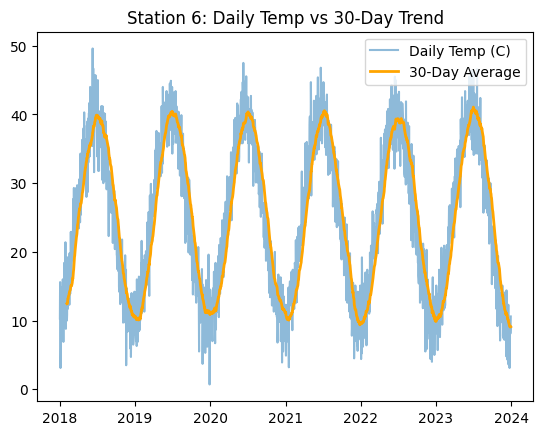

In [542]:
#visualizing it because i cant tell if it worked 
import matplotlib.pyplot as plt 

#doing a line graph so i can see the changes over time 
plt.plot(station_6['date'], station_6['temp_avg_c'], label='Daily Temp (C)', alpha=0.5)
plt.plot(station_6['date'], station_6['30_day_pd'], label='30-Day Average', color='orange', linewidth=2)

plt.title('Station 6: Daily Temp vs 30-Day Trend')
plt.legend()
plt.show()

This graph shows that the average temperature fluctuates regularly every year. There are not many year by year changes, and it looks like a sine graph pattern. There is great fluctation within each year. 

In [543]:
#calculate year over year temp changes 
yearly_temps = merged_df.groupby('years')['temp_avg_c'].mean()

yoy_change = yearly_temps.diff()

yoy_change


years
2018         NaN
2019   -0.057286
2020   -0.056777
2021    0.063841
2022   -0.039543
2023   -0.039486
Name: temp_avg_c, dtype: float64

I added the years column to the merged df because I kept having to reference the years. After calculating the differences between each year, you can see the average temperature gets cooler every year compared to the previous year. This suggests there is a trend towards cooler temperatures in this dataset. 

In [551]:
#identify any seasonal patterns in temp ranges 
#use months? 

merged_df['month'] = merged_df['date'].dt.month

#Group by month and calculate the average temp range

#the winter seasons are 12, 1, 2 
#spring is 3, 4 ,5 
#summer is 6, 7 ,8 
#fall is 9, 10 ,11

#i want to do seasons, not months 
def season(month):
    if month in [12, 1, 2]: 
        return 'winter'
    if month in [3, 4, 5]:
        return 'spring'
    if month in [6, 7, 8]:
        return 'summer'
    if month in [9, 10, 11]:
        return 'fall'

merged_df['season'] = merged_df['month'].apply(season)

# Checking to make sure it worked
#print(merged_df[['date', 'month', 'season']])

#doing the seasonal patterns
seasonal_patterns = merged_df.groupby('season')['range_temp_c'].mean()

print(seasonal_patterns)

monthly_patterns = merged_df.groupby('month')['range_temp_c'].mean()

monthly_patterns

season
fall      11.018768
spring    10.972896
summer    11.014741
winter    10.998878
Name: range_temp_c, dtype: float64


month
1     11.018382
2     10.957852
3     10.986989
4     10.975068
5     10.956651
6     11.070082
7     10.990364
8     10.985827
9     11.021068
10    11.050498
11    10.983461
12    11.016671
Name: range_temp_c, dtype: float64

Based on the seasons output, the season with the highest temp range was fall, with summer close behind. This is for all of the stations in all of the regions. I also looked at the monthly ranges just to make sure the seasons output made sense.

date
2018-01-31     9.861994
2018-02-28    14.624071
2018-03-31    21.883836
2018-04-30    29.416889
2018-05-31    35.208225
Freq: ME, Name: temp_avg_c, dtype: float64


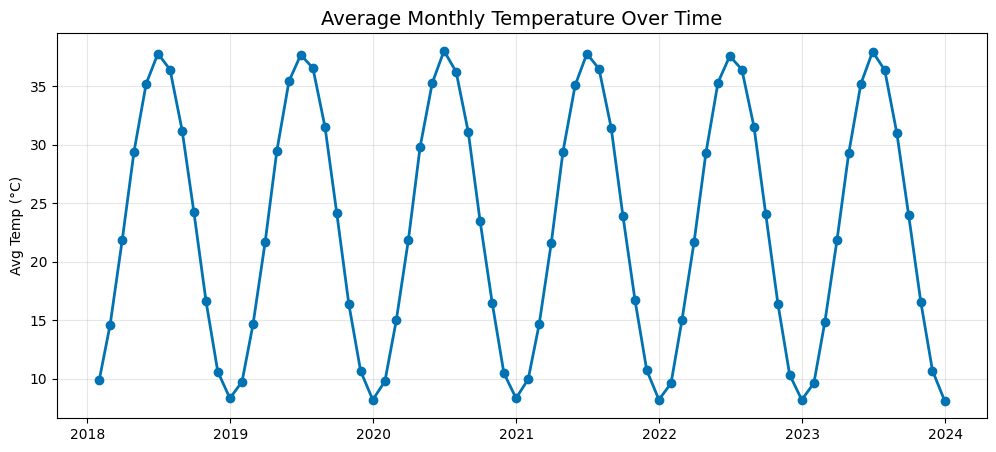

In [554]:
#resample the daily data to monthly avgs and visualize 
time_series_df = merged_df.set_index('date')

monthly_data = time_series_df['temp_avg_c'].resample('ME').mean()

print(monthly_data.head())

#making the visualization
fig, ax = plt.subplots(figsize=(12, 5))

# Plot the monthly averages
# Note: Since monthly_data is a Series, the index (dates) is automatically the x-axis
ax.plot(monthly_data.index, monthly_data.values, 
        marker='o', linestyle='-', linewidth=2, color='#0173B2')

ax.set_title('Average Monthly Temperature Over Time', fontsize=14)
ax.set_ylabel('Avg Temp (°C)')
ax.grid(True, alpha=0.3)

plt.show()

## Key Questions:

How do rolling averages help you understand temperature patterns differently than daily measurements?
Based on your analysis, is there evidence of a warming or cooling trend at the station(s) you examined? What does the year-over-year data show?

The rolling averages help you understand temperature patterns by seeing how the temperatures change throughout each year and the entire 6 years within the dataset. When you just look at the daily measurements, it may look like things change from day to day, but you can't tell a long-term pattern without looking at the bigger picture. I made a graph to look at the 30 day rolling period because it helped me better understand it. This showed me that while there didn't seem to be much obvious change in the pattern year to year, within each year there was a clear and consistent cycle, that mimicked a sine wave, of how the temperature changed.

However, based on the year over year changes, the average temperature was changing slightly each year, getting cooler and cooler. This was a consistent pattern over the entire 6 years from the dataset. 